# Procedural CCLE protein prediction partitions

This notebook gives a compact, procedural answer to:

> Which proteins are already predicted well by same-gene proxy models, which are rescued by ElasticNet, which are rescued by XGBoost, and which remaining proteins are rescued by scTranslator predictions?

The main procedural order is:

```text
same-gene proxy Pearson/Spearman → ElasticNet → XGBoost → scTranslator
```

The notebook focuses on horizontal stacked bar-partition plots. It avoids broad distribution plots and uses threshold sweeps instead.

Main analyses:

1. Same-gene Pearson and Spearman proxy performance.
2. Procedural Pearson partitions for thresholds 0.30, 0.50, and 0.70.
3. Compact Pearson threshold sweep.
4. Proxy-correlation threshold inspection.
5. MSE inspection without a fixed MSE threshold.
6. Final scTranslator rescue analysis among proteins not predicted well by proxy, ENet, or XGB.

In [1]:
from pathlib import Path
import hashlib
import json
import lzma
import pickle
import re
import warnings

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------
# Project paths
# ---------------------------------------------------------------------
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"

X_PATH = DATA_DIR / "transcriptomics_filtered.joblib"
Y_PATH = DATA_DIR / "proteomics_matched.joblib"
PEARSON_PATH = DATA_DIR / "full_pearson100.joblib"
SPEARMAN_PATH = DATA_DIR / "full_spearman100.joblib"

MODEL_DIRS = {
    "xgb": ROOT / "results_xgb",
    "xgb_zbig": ROOT / "res_xgb_zbig",
    "enet": ROOT / "results_enet",
    "enet_zbig": ROOT / "res_enet_zbig",
}

SCTRANSLATOR_BUNDLE_PATHS = {
    "2M": ROOT / "sc_predictions_2M.npz",
    "160K": ROOT / "sc_predictions_160K.npz",
    "10K": ROOT / "sc_predictions_10K.npz",
}

# ---------------------------------------------------------------------
# Analysis knobs
# ---------------------------------------------------------------------
RANDOM_SEED = 42
TEST_FRACTION = 0.20

# Main requested Pearson thresholds.
PEARSON_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]

# Denser sweep for sensitivity plots.
PEARSON_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 0.85, 0.05)]

# Same-gene proxy full-correlation threshold sweep.
PROXY_CORR_THRESHOLDS = [round(x, 2) for x in np.arange(0.00, 0.85, 0.10)]

# If True, proxy prediction is fitted as y_protein ~ RNA_gene on train samples.
# If False, raw same-gene RNA values are used directly, matching the previous notebook behavior.
SCALE_GENE_PROXY_WITH_TRAIN_LINEAR_MODEL = False

# Plotting controls.
FIGURE_DIR = ROOT / "procedural_figures"
EXPORT_TABLE_DIR = ROOT / "procedural_tables"
SAVE_OUTPUTS = False

FIGURE_DIR.mkdir(exist_ok=True)
EXPORT_TABLE_DIR.mkdir(exist_ok=True)

print("Root:", ROOT)
print("Data dir:", DATA_DIR)
print("Model folders:")
for name, folder in MODEL_DIRS.items():
    print(f"  {name:10s}: {folder}  exists={folder.exists()}")
print("\nscTranslator bundles:")
for name, path in SCTRANSLATOR_BUNDLE_PATHS.items():
    print(f"  {name:5s}: {path}  exists={path.exists()}")

Root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Data dir: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data
Model folders:
  xgb       : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_xgb  exists=True
  xgb_zbig  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_xgb_zbig  exists=True
  enet      : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_enet  exists=True
  enet_zbig : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_enet_zbig  exists=True

scTranslator bundles:
  2M   : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_2M.npz  exists=True
  160K : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_160K.npz  exists=True
  10K  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_1

## 1. Load transcriptomics, proteomics, and correlation matrices

The proteomics table is oriented as samples × proteins. If the loaded object is proteins × samples, it is transposed automatically.

In [2]:
def require_file(path: Path):
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")
    return path

for p in [X_PATH, Y_PATH, PEARSON_PATH, SPEARMAN_PATH]:
    require_file(p)

X_raw = joblib.load(X_PATH)
Y_raw = joblib.load(Y_PATH)
pearson_corr_obj = joblib.load(PEARSON_PATH)
spearman_corr_obj = joblib.load(SPEARMAN_PATH)

X = X_raw.copy()
Y0 = Y_raw.copy()

X.index = X.index.map(str)
X.columns = X.columns.map(str)
Y0.index = Y0.index.map(str)
Y0.columns = Y0.columns.map(str)

# Detect proteomics orientation and convert to rows=samples, columns=proteins.
x_samples = set(X.index)
y_index_overlap = len(x_samples & set(Y0.index))
y_column_overlap = len(x_samples & set(Y0.columns))

if y_index_overlap >= y_column_overlap:
    Y = Y0.copy()
    proteomics_orientation = "samples_as_rows__proteins_as_columns"
else:
    Y = Y0.T.copy()
    proteomics_orientation = "proteins_as_rows__samples_as_columns__transposed"

Y.index = Y.index.map(str)
Y.columns = Y.columns.map(str)

common_samples = X.index.intersection(Y.index)
X = X.loc[common_samples].copy()
Y = Y.loc[common_samples].copy()

# scTranslator predictions are compared to this ground-truth table.
# If the project already defines GT_scaled upstream, this notebook uses Y as the default equivalent.
GT_scaled = Y.copy()

protein_universe = pd.Index(Y.columns.astype(str)).unique()

print("Loaded data")
print("- Transcriptomics shape:", X.shape, "(samples x genes)")
print("- Proteomics shape:     ", Y.shape, "(samples x proteins)")
print("- Proteomics orientation:", proteomics_orientation)
print("- Common samples:", len(common_samples))
print("- Proteins in universe:", len(protein_universe))
print("- First samples:", list(common_samples[:5]))
print("- First genes:", list(X.columns[:5]))
print("- First proteins:", list(Y.columns[:5]))

print("\nCorrelation objects:")
print("- Pearson type:", type(pearson_corr_obj), "shape:", getattr(pearson_corr_obj, "shape", None))
print("- Spearman type:", type(spearman_corr_obj), "shape:", getattr(spearman_corr_obj, "shape", None))

Loaded data
- Transcriptomics shape: (369, 22614) (samples x genes)
- Proteomics shape:      (369, 5113) (samples x proteins)
- Proteomics orientation: samples_as_rows__proteins_as_columns
- Common samples: 369
- Proteins in universe: 5113
- First samples: ['MDAMB468_BREAST', 'SH4_SKIN', 'AU565_BREAST', 'KMRC1_KIDNEY', 'CAL51_BREAST']
- First genes: ['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2ML1']
- First proteins: ['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1']

Correlation objects:
- Pearson type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)
- Spearman type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)


## 2. Helper functions

These functions load saved `.h5` results, recover the exact test split, compute metrics, and build same-gene proxy predictions without imposing a fixed proxy-correlation threshold.

In [3]:
def compute_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)

    out = {
        "test_mse": np.nan,
        "test_pearson_corr": np.nan,
        "test_cosine_similarity": np.nan,
        "n_test_used": int(mask.sum()),
    }
    if mask.sum() == 0:
        return out

    yt = y_true[mask]
    yp = y_pred[mask]
    out["test_mse"] = float(np.mean((yt - yp) ** 2))

    if len(yt) >= 2 and np.std(yt) > 0 and np.std(yp) > 0:
        out["test_pearson_corr"] = float(np.corrcoef(yt, yp)[0, 1])

    denom = float(np.linalg.norm(yt) * np.linalg.norm(yp))
    if denom > 0:
        out["test_cosine_similarity"] = float(np.dot(yt, yp) / denom)

    return out


def safe_float(x):
    try:
        if x is None:
            return np.nan
        v = float(x)
        return v if np.isfinite(v) else np.nan
    except Exception:
        return np.nan


def safe_int(x):
    try:
        if x is None:
            return np.nan
        return int(x)
    except Exception:
        return np.nan


def _decode_json_dataset(ds):
    data = ds[()]

    if isinstance(data, bytes):
        raw = data
    elif isinstance(data, str):
        raw = data.encode("utf-8")
    else:
        arr = np.asarray(data)
        if arr.dtype.kind in {"S", "U", "O"}:
            raw = b"".join(
                x if isinstance(x, bytes) else str(x).encode("utf-8")
                for x in arr.ravel()
            )
        else:
            raw = bytes(arr.astype(np.uint8).ravel())

    return json.loads(raw.decode("utf-8"))


def read_json_dataset(h5, candidates):
    for key in candidates:
        if key in h5:
            try:
                return _decode_json_dataset(h5[key])
            except Exception:
                pass
    return {}


def get_attr_float(group_or_h5, key):
    try:
        if group_or_h5 is not None and key in group_or_h5.attrs:
            return safe_float(group_or_h5.attrs.get(key))
    except Exception:
        pass
    return np.nan


def get_attr_int(group_or_h5, key):
    try:
        if group_or_h5 is not None and key in group_or_h5.attrs:
            return safe_int(group_or_h5.attrs.get(key))
    except Exception:
        pass
    return np.nan


def protein_from_filename(path: Path):
    name = path.stem
    for token in ["_xgb_8020_", "_enet_8020_"]:
        if token in name:
            return name.split(token)[0]
    return name.split("_")[0]


def parse_filename_info(path: Path):
    path = Path(path)
    stem = path.stem
    tokens = stem.split("_")

    model_family = "unknown"
    if "_xgb_8020_" in stem:
        model_family = "xgb"
    elif "_enet_8020_" in stem:
        model_family = "enet"

    protein = protein_from_filename(path)

    normalization = "unknown"
    grid_preset = "unknown"
    select_k = np.nan

    known_norms = {
        "none", "zscore", "rank", "ranking", "binning",
        "qbin5", "qbin10", "qbin20", "qbin50", "qbin100",
    }

    for tok in tokens:
        if tok in known_norms or re.fullmatch(r"qbin\d+", tok):
            normalization = tok
            break

    for tok in tokens:
        if tok in {"tiny", "fast", "current"}:
            grid_preset = tok
            break

    for tok in tokens:
        m = re.fullmatch(r"k(\d+)", tok)
        if m:
            select_k = int(m.group(1))
            break

    return {
        "protein": protein,
        "model_family": model_family,
        "normalization": normalization,
        "grid_preset": grid_preset,
        "select_k": select_k,
    }


def _read_best_params(h5, summary):
    for key in ["best_params", "params", "model_params"]:
        if key in summary:
            return summary.get(key)

    for key in ["model/best_params_json", "model/params_json"]:
        if key in h5:
            try:
                return _decode_json_dataset(h5[key])
            except Exception:
                pass

    return {}


def load_h5_summary(path: Path, source_label: str):
    path = Path(path)
    info = parse_filename_info(path)

    row = {
        "protein": info["protein"],
        "run_label": None,
        "model_family": info["model_family"],
        "source_folder": source_label,
        "normalization": info["normalization"],
        "grid_preset": info["grid_preset"],
        "select_k": info["select_k"],
        "h5_path": str(path),
        "file": path.name,
        "file_size_mb": path.stat().st_size / (1024 ** 2),
        "test_mse": np.nan,
        "test_pearson_corr": np.nan,
        "test_cosine_similarity": np.nan,
        "selected_feature_count": np.nan,
        "train_n": np.nan,
        "test_n": np.nan,
        "best_params": {},
        "load_error": None,
    }

    try:
        with h5py.File(path, "r") as h5:
            root_attrs = dict(h5.attrs)
            metrics_group = h5.get("metrics", None)
            model_group = h5.get("model", None)
            samples_group = h5.get("samples", None)

            summary = read_json_dataset(
                h5,
                ["summary/json", "metrics/json", "metrics/summary_json", "metrics/summary"],
            )

            row["protein"] = str(summary.get("protein") or root_attrs.get("protein") or row["protein"])
            row["normalization"] = str(summary.get("normalization") or root_attrs.get("normalization") or row["normalization"])
            row["model_family"] = str(summary.get("model_family") or row["model_family"])
            row["grid_preset"] = str(
                summary.get("grid_preset")
                or summary.get("grid")
                or root_attrs.get("grid_preset", row["grid_preset"])
                or row["grid_preset"]
            )
            row["select_k"] = safe_int(
                summary.get("select_k")
                or root_attrs.get("select_k", row["select_k"])
                or row["select_k"]
            )

            row["test_mse"] = safe_float(summary.get("test_mse", summary.get("mse", np.nan)))
            if not np.isfinite(row["test_mse"]):
                row["test_mse"] = get_attr_float(metrics_group, "test_mse")
            if not np.isfinite(row["test_mse"]):
                row["test_mse"] = get_attr_float(metrics_group, "mse")
            if not np.isfinite(row["test_mse"]):
                row["test_mse"] = get_attr_float(h5, "test_mse")

            row["test_pearson_corr"] = safe_float(
                summary.get("test_pearson_corr", summary.get("pearson_corr", np.nan))
            )
            if not np.isfinite(row["test_pearson_corr"]):
                row["test_pearson_corr"] = get_attr_float(metrics_group, "test_pearson_corr")
            if not np.isfinite(row["test_pearson_corr"]):
                row["test_pearson_corr"] = get_attr_float(metrics_group, "pearson_corr")
            if not np.isfinite(row["test_pearson_corr"]):
                row["test_pearson_corr"] = get_attr_float(h5, "test_pearson_corr")

            row["test_cosine_similarity"] = safe_float(
                summary.get(
                    "test_cosine_similarity",
                    summary.get(
                        "cosine_similarity",
                        summary.get("vector_cosine_similarity_all_loo", np.nan),
                    ),
                )
            )
            if not np.isfinite(row["test_cosine_similarity"]):
                row["test_cosine_similarity"] = get_attr_float(metrics_group, "test_cosine_similarity")
            if not np.isfinite(row["test_cosine_similarity"]):
                row["test_cosine_similarity"] = get_attr_float(metrics_group, "cosine_similarity")
            if not np.isfinite(row["test_cosine_similarity"]):
                row["test_cosine_similarity"] = get_attr_float(metrics_group, "vector_cosine_similarity_all_loo")
            if not np.isfinite(row["test_cosine_similarity"]):
                row["test_cosine_similarity"] = get_attr_float(h5, "test_cosine_similarity")

            train_samples_from_summary = summary.get("train_samples", [])
            test_samples_from_summary = summary.get("test_samples", [])
            if isinstance(train_samples_from_summary, list):
                row["train_n"] = len(train_samples_from_summary)
            if isinstance(test_samples_from_summary, list):
                row["test_n"] = len(test_samples_from_summary)

            if samples_group is not None:
                if "train_samples" in samples_group:
                    row["train_n"] = len(samples_group["train_samples"])
                if "test_samples" in samples_group:
                    row["test_n"] = len(samples_group["test_samples"])

            selected_features = summary.get("selected_features", None)
            if isinstance(selected_features, list):
                row["selected_feature_count"] = len(selected_features)

            if model_group is not None:
                if "selected_feature_count" in model_group.attrs:
                    row["selected_feature_count"] = safe_int(model_group.attrs.get("selected_feature_count"))
                elif "selected_features" in model_group:
                    row["selected_feature_count"] = len(model_group["selected_features"])

            row["best_params"] = _read_best_params(h5, summary)

    except Exception as e:
        row["load_error"] = f"{type(e).__name__}: {e}"

    if row["model_family"] == "unknown":
        if "xgb" in str(source_label).lower():
            row["model_family"] = "xgb"
        elif "enet" in str(source_label).lower():
            row["model_family"] = "enet"

    label_bits = [str(source_label), str(row["normalization"])]
    if row["grid_preset"] not in {"", "unknown", "None", "nan"}:
        label_bits.append(str(row["grid_preset"]))
    if pd.notna(row["select_k"]):
        label_bits.append(f"k{int(row['select_k'])}")
    row["run_label"] = " | ".join(label_bits)

    return row


def _decode_h5_string_array(x):
    arr = np.asarray(x)
    if arr.shape == ():
        arr = arr.reshape(1)

    out = []
    for v in arr.ravel():
        if isinstance(v, bytes):
            out.append(v.decode("utf-8"))
        elif isinstance(v, np.bytes_):
            out.append(bytes(v).decode("utf-8"))
        else:
            out.append(str(v))
    return pd.Index(out)


def _find_key_recursive(obj, target_keys):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k in target_keys:
                return v
        for v in obj.values():
            found = _find_key_recursive(v, target_keys)
            if found is not None:
                return found
    elif isinstance(obj, list):
        for v in obj:
            found = _find_key_recursive(v, target_keys)
            if found is not None:
                return found
    return None


def read_test_samples_from_h5(path):
    direct_keys = [
        "samples/test_samples",
        "test_samples",
        "data/test_samples",
        "split/test_samples",
        "splits/test_samples",
        "sample_names/test_samples",
    ]
    json_keys = ["summary/json", "metrics/json", "metrics/summary_json", "metrics/summary"]

    with h5py.File(str(path), "r") as h5:
        for key in direct_keys:
            if key in h5:
                return _decode_h5_string_array(h5[key][()])

        for key in json_keys:
            if key in h5:
                try:
                    obj = _decode_json_dataset(h5[key])
                    found = _find_key_recursive(
                        obj,
                        target_keys={"test_samples", "test_sample_names", "samples_test"},
                    )
                    if found is not None:
                        return pd.Index([str(x) for x in found])
                except Exception:
                    pass
    return None


def split_hash(samples):
    samples = pd.Index(samples.astype(str))
    key = "\n".join(sorted(samples))
    return hashlib.sha1(key.encode("utf-8")).hexdigest()[:12]


def linear_scale_prediction(x_train, y_train, x_test):
    x_train = np.asarray(x_train, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    x_test = np.asarray(x_test, dtype=float)
    mask = np.isfinite(x_train) & np.isfinite(y_train)
    if mask.sum() < 2 or np.std(x_train[mask]) == 0:
        return x_test
    a, b = np.polyfit(x_train[mask], y_train[mask], deg=1)
    return a * x_test + b


def build_same_name_corr_lookup_fast(corr_obj, possible_proteins):
    possible_proteins = [str(p) for p in possible_proteins]
    possible_set = set(possible_proteins)
    lookup = {}

    if isinstance(corr_obj, pd.DataFrame):
        df = corr_obj
        index_map = {str(v): i for i, v in enumerate(df.index)}
        column_map = {str(v): i for i, v in enumerate(df.columns)}
        common = possible_set.intersection(index_map).intersection(column_map)

        if len(common) > 0:
            for p in common:
                try:
                    lookup[p] = float(df.iat[index_map[p], column_map[p]])
                except Exception:
                    pass
            return lookup

        lower_cols = {str(c).lower(): c for c in df.columns}
        prot_candidates = ["protein", "protein_name", "target", "target_protein"]
        gene_candidates = ["gene", "feature", "rna", "transcript", "transcript_gene"]
        corr_candidates = [
            c for c in df.columns
            if "corr" in str(c).lower()
            or "pearson" in str(c).lower()
            or "spearman" in str(c).lower()
        ]
        prot_col = next((lower_cols[c] for c in prot_candidates if c in lower_cols), None)
        gene_col = next((lower_cols[c] for c in gene_candidates if c in lower_cols), None)
        corr_col = corr_candidates[0] if corr_candidates else None

        if prot_col and gene_col and corr_col:
            prot_vals = df[prot_col].astype(str)
            gene_vals = df[gene_col].astype(str)
            mask = prot_vals.isin(possible_set) & gene_vals.isin(possible_set) & (prot_vals == gene_vals)
            sub = df.loc[mask, [prot_col, corr_col]]
            for _, row in sub.iterrows():
                try:
                    lookup[str(row[prot_col])] = float(row[corr_col])
                except Exception:
                    pass
        return lookup

    if isinstance(corr_obj, dict):
        for p in possible_proteins:
            val = None
            if p in corr_obj:
                obj = corr_obj[p]
                if isinstance(obj, pd.Series):
                    idx_map = {str(v): i for i, v in enumerate(obj.index)}
                    if p in idx_map:
                        val = obj.iloc[idx_map[p]]
                elif isinstance(obj, dict):
                    if p in obj:
                        val = obj[p]
                else:
                    val = obj
            elif (p, p) in corr_obj:
                val = corr_obj[(p, p)]
            if val is not None:
                try:
                    lookup[p] = float(val)
                except Exception:
                    pass
        return lookup

    return lookup


def add_family_group(df):
    df = df.copy()
    labels = df.get("run_label", pd.Series(index=df.index, dtype=object)).astype(str).str.lower()
    fam = df.get("model_family", pd.Series(index=df.index, dtype=object)).astype(str).str.lower()

    out = np.full(len(df), "other", dtype=object)
    out[(fam.str.contains("proxy") | labels.str.contains("proxy") | labels.str.contains("same_gene")).to_numpy()] = "proxy"
    out[(fam.str.contains("enet") | labels.str.contains("enet")).to_numpy()] = "enet"
    out[(fam.str.contains("xgb") | labels.str.contains("xgb")).to_numpy()] = "xgb"
    out[(fam.str.contains("sctranslator") | labels.str.contains("sctranslator")).to_numpy()] = "sctranslator"

    df["family_group"] = out
    return df

## 3. Load saved ENet/XGB result summaries

Only metrics and metadata are loaded from `.h5` files. Models are not retrained.

In [4]:
model_rows = []
folder_counts = {}

for label, folder in MODEL_DIRS.items():
    folder = Path(folder)
    files = sorted(folder.glob("*.h5")) if folder.exists() else []
    folder_counts[label] = len(files)

    for path in files:
        row = load_h5_summary(path, label)
        if "h5_path" not in row:
            row["h5_path"] = str(path)
        model_rows.append(row)

model_results = pd.DataFrame(model_rows)

if len(model_results):
    for c in [
        "test_mse",
        "test_pearson_corr",
        "test_cosine_similarity",
        "selected_feature_count",
        "train_n",
        "test_n",
        "select_k",
        "file_size_mb",
    ]:
        if c in model_results.columns:
            model_results[c] = pd.to_numeric(model_results[c], errors="coerce")

    model_results = add_family_group(model_results)

print("Saved model file counts")
for label, n in folder_counts.items():
    print(f"- {label:12s}: {n:6d} H5 files")

print("\nSaved model result table")
print("- Saved model rows:", len(model_results))
print("- Unique proteins: ", model_results["protein"].nunique() if len(model_results) and "protein" in model_results.columns else 0)

if len(model_results) and "load_error" in model_results.columns:
    n_errors = int(model_results["load_error"].notna().sum())
    print("- H5 load errors:  ", n_errors)
    if n_errors:
        display(model_results.loc[model_results["load_error"].notna(), ["h5_path", "load_error"]].head(10))

if len(model_results):
    display(
        model_results.groupby(["family_group", "run_label"])["protein"]
        .nunique()
        .sort_values(ascending=False)
        .to_frame("proteins")
    )
    display(model_results.head())
else:
    raise RuntimeError("No saved ENet/XGB .h5 result files were found in MODEL_DIRS.")

Saved model file counts
- xgb         :  20462 H5 files
- xgb_zbig    :   5113 H5 files
- enet        :  20602 H5 files
- enet_zbig   :   5113 H5 files

Saved model result table
- Saved model rows: 51290
- Unique proteins:  5113
- H5 load errors:   0


proteins
family_group run_label                                    
enet         enet | none | fast | k2000               5113
             enet | ranking | fast | k2000            5113
             enet | unknown | fast | k2000            5113
             enet | zscore | fast | k2000             5113
             enet_zbig | zscore | fast | k5000        5113
xgb          xgb | none | fast | k2000                5113
             xgb | qbin50 | fast | k2000              5113
             xgb | rank | fast | k2000                5113
             xgb | zscore | fast | k2000              5113
             xgb_zbig | zscore | current | k5000      5113
enet         enet | none | fast | k500                  50
             enet | unknown | fast | k500               50
             enet | zscore | fast | k500                50
xgb          xgb | none | tiny | k50                     5
             xgb | qbin50 | tiny | k50                   5

,protein,run_label,model_family,source_folder,normalization,grid_preset,select_k,h5_path,file,file_size_mb,test_mse,test_pearson_corr,test_cosine_similarity,selected_feature_count,train_n,test_n,best_params,load_error,family_group
0,A2M,xgb | none | fast | k2000,xgb,xgb,none,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb
1,A2M,xgb | none | tiny | k50,xgb,xgb,none,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,0.753375,0.477427,0.558124,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,xgb
2,A2M,xgb | qbin50 | fast | k2000,xgb,xgb,qbin50,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,0.751074,0.466232,0.560768,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb
3,A2M,xgb | qbin50 | tiny | k50,xgb,xgb,qbin50,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,0.778497,0.451791,0.539072,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,xgb
4,A2M,xgb | rank | fast | k2000,xgb,xgb,rank,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb


## 4. Recover the exact H5 test split

The proxy models and scTranslator predictions are evaluated on the same test samples used by the saved ENet/XGB `.h5` files.

In [5]:
if "h5_path" not in model_results.columns:
    raise RuntimeError("model_results has no h5_path column, so the H5 test split cannot be read.")

split_rows = []
split_samples_by_hash = {}

h5_paths = (
    model_results["h5_path"]
    .dropna()
    .astype(str)
    .loc[lambda s: s.str.len() > 0]
    .unique()
)

for path in h5_paths:
    try:
        h5_test_samples = read_test_samples_from_h5(path)
        if h5_test_samples is None:
            split_rows.append({"h5_path": path, "readable": False, "test_n": np.nan, "split_hash": None})
            continue

        h5_test_samples = pd.Index(h5_test_samples.astype(str))
        h = split_hash(h5_test_samples)
        split_samples_by_hash[h] = h5_test_samples
        split_rows.append({"h5_path": path, "readable": True, "test_n": len(h5_test_samples), "split_hash": h})

    except Exception as e:
        split_rows.append({
            "h5_path": path,
            "readable": False,
            "test_n": np.nan,
            "split_hash": None,
            "error": f"{type(e).__name__}: {e}",
        })

h5_split_check = pd.DataFrame(split_rows)

print("H5 test split readability")
display(
    h5_split_check
    .groupby(["readable", "split_hash"], dropna=False)
    .agg(files=("h5_path", "count"), test_n=("test_n", "median"))
    .reset_index()
    .sort_values(["readable", "files"], ascending=[False, False])
)

readable = h5_split_check[h5_split_check["readable"]].copy()
if readable.empty:
    raise RuntimeError(
        "Could not read test_samples from any H5 file. "
        "The saved XGB/ENet files probably do not store the test split."
    )

unique_hashes = readable["split_hash"].dropna().unique()
if len(unique_hashes) != 1:
    display(
        readable
        .groupby("split_hash")
        .agg(files=("h5_path", "count"), test_n=("test_n", "median"))
        .sort_values("files", ascending=False)
    )
    raise RuntimeError(
        f"Found {len(unique_hashes)} different H5 test splits. "
        "A single proxy/scTranslator split cannot fairly match all models."
    )

model_split_hash = unique_hashes[0]
model_test_samples = pd.Index(split_samples_by_hash[model_split_hash].astype(str))
common_samples_index = pd.Index(np.asarray(common_samples, dtype=str))

test_samples = model_test_samples.intersection(common_samples_index)
train_samples = pd.Index([s for s in common_samples_index if s not in set(test_samples)])

print("\nUsing exact XGB/ENet H5 test split")
print("- Split hash:", model_split_hash)
print("- Test samples:", len(test_samples))
print("- Train samples:", len(train_samples))
print("- Test fraction:", len(test_samples) / len(common_samples_index))
print("- First test samples:", list(test_samples[:5]))

H5 test split readability


,readable,split_hash,files,test_n
0,True,d0750f1c44a2,51290,74.0



Using exact XGB/ENet H5 test split
- Split hash: d0750f1c44a2
- Test samples: 74
- Train samples: 295
- Test fraction: 0.2005420054200542
- First test samples: ['HDMYZ_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'JHH5_LIVER', 'CAOV3_OVARY', 'K562_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'NCIH1693_LUNG']


## 5. Build same-gene Pearson and Spearman proxy models

Unlike the previous notebook, this builds **all available same-gene proxy predictions first** and stores the full same-gene correlation as metadata. Thresholds are applied later during plotting.

In [6]:
def build_same_gene_proxy_all_from_lookup(corr_lookup, proxy_type):
    rows = []
    possible = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

    print(f"\nBuilding same-gene {proxy_type} proxy")
    print("- Same-name protein/gene pairs possible:", len(possible))
    print("- Correlation lookup entries:", len(corr_lookup))
    print("- Test samples used:", len(test_samples))
    print("- Train samples used:", len(train_samples))

    for protein in possible:
        c = corr_lookup.get(protein, np.nan)
        if not np.isfinite(c):
            continue

        y_true = Y.loc[test_samples, protein].to_numpy(dtype=float)
        x_test = X.loc[test_samples, protein].to_numpy(dtype=float)

        if SCALE_GENE_PROXY_WITH_TRAIN_LINEAR_MODEL:
            x_train = X.loc[train_samples, protein].to_numpy(dtype=float)
            y_train = Y.loc[train_samples, protein].to_numpy(dtype=float)
            y_pred = linear_scale_prediction(x_train, y_train, x_test)
            variant = "scaled_train_linear"
        else:
            y_pred = x_test
            variant = "raw_gene_value"

        metrics = compute_metrics(y_true, y_pred)

        rows.append({
            "protein": protein,
            "run_label": f"proxy_same_gene_{proxy_type}",
            "model_family": "same_gene_proxy",
            "family_group": "proxy",
            "source_folder": f"proxy_same_gene_{proxy_type}",
            "normalization": variant,
            "h5_path": "",
            "proxy_type": proxy_type,
            "same_gene_corr_full": float(c),
            "test_mse": metrics["test_mse"],
            "test_pearson_corr": metrics["test_pearson_corr"],
            "test_cosine_similarity": metrics["test_cosine_similarity"],
            "n_test_used": metrics.get("n_test_used", np.nan),
            "selected_feature_count": 1,
            "train_n": len(train_samples),
            "test_n": len(test_samples),
            "split_hash": model_split_hash,
            "best_params": {
                "baseline": "same_name_gene_value",
                "proxy_type": proxy_type,
                "scaled": SCALE_GENE_PROXY_WITH_TRAIN_LINEAR_MODEL,
                "test_split_source": "read_from_xgb_enet_h5",
            },
        })

    return pd.DataFrame(rows)

possible_same_name = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

print("Precomputing same-name Pearson lookup...")
pearson_lookup = build_same_name_corr_lookup_fast(pearson_corr_obj, possible_same_name)

print("Precomputing same-name Spearman lookup...")
spearman_lookup = build_same_name_corr_lookup_fast(spearman_corr_obj, possible_same_name)

pearson_proxy = build_same_gene_proxy_all_from_lookup(pearson_lookup, proxy_type="pearson")
spearman_proxy = build_same_gene_proxy_all_from_lookup(spearman_lookup, proxy_type="spearman")

proxy_results = pd.concat([pearson_proxy, spearman_proxy], ignore_index=True, sort=False)
proxy_results = add_family_group(proxy_results)

all_results = pd.concat([model_results, proxy_results], ignore_index=True, sort=False)
all_results = add_family_group(all_results)

print("\nProxy rows built without proxy-correlation filtering")
print("- Pearson proxy rows: ", len(pearson_proxy))
print("- Spearman proxy rows:", len(spearman_proxy))
print("- Total proxy rows:   ", len(proxy_results))
print("\nCombined result table")
print("- Saved model rows:", len(model_results))
print("- Proxy rows:      ", len(proxy_results))
print("- Total rows:      ", len(all_results))
print("- Unique proteins: ", all_results["protein"].nunique())

display(
    all_results.groupby(["family_group", "run_label"])["protein"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame("proteins")
)

display(
    all_results.groupby("family_group")
    .agg(
        rows=("protein", "count"),
        proteins=("protein", "nunique"),
        pearson_nonmissing=("test_pearson_corr", lambda s: s.notna().sum()),
        mse_nonmissing=("test_mse", lambda s: s.notna().sum()),
    )
)

Precomputing same-name Pearson lookup...
Precomputing same-name Spearman lookup...

Building same-gene pearson proxy
- Same-name protein/gene pairs possible: 4843
- Correlation lookup entries: 4843
- Test samples used: 74
- Train samples used: 295

Building same-gene spearman proxy
- Same-name protein/gene pairs possible: 4843
- Correlation lookup entries: 4843
- Test samples used: 74
- Train samples used: 295

Proxy rows built without proxy-correlation filtering
- Pearson proxy rows:  4843
- Spearman proxy rows: 4843
- Total proxy rows:    9686

Combined result table
- Saved model rows: 51290
- Proxy rows:       9686
- Total rows:       60976
- Unique proteins:  5113


proteins
family_group run_label                                    
enet         enet | none | fast | k2000               5113
             enet_zbig | zscore | fast | k5000        5113
xgb          xgb | zscore | fast | k2000              5113
             xgb | rank | fast | k2000                5113
             xgb | qbin50 | fast | k2000              5113
             xgb | none | fast | k2000                5113
             xgb_zbig | zscore | current | k5000      5113
enet         enet | zscore | fast | k2000             5113
             enet | unknown | fast | k2000            5113
             enet | ranking | fast | k2000            5113
proxy        proxy_same_gene_spearman                 4843
             proxy_same_gene_pearson                  4843
enet         enet | zscore | fast | k500                50
             enet | none | fast | k500                  50
             enet | unknown | fast | k500               50
xgb          xgb | none | tiny | k50                     5
             xgb | qbin50 | tiny | k50                   5

,rows,proteins,pearson_nonmissing,mse_nonmissing
family_group,,,,
enet,25715,5113,24642,25715
proxy,9686,4843,9686,9686
xgb,25575,5113,25575,25575


## 6. Best-per-family tables

For the procedural cascade, each family contributes its best result per protein:

- Proxy: best of same-gene Pearson and same-gene Spearman proxy.
- ENet: best ENet result per protein.
- XGB: best XGB result per protein.

For Pearson, higher is better. For MSE, lower is better.

In [7]:
def best_per_protein(df, metric, higher=True):
    if df is None or len(df) == 0 or metric not in df.columns:
        return pd.DataFrame()
    use = df.dropna(subset=["protein", metric]).copy()
    if use.empty:
        return use
    use["protein"] = use["protein"].astype(str)
    use = use.sort_values(metric, ascending=not higher)
    return use.drop_duplicates("protein", keep="first").reset_index(drop=True)


def best_family(metric, family, higher=True):
    return best_per_protein(all_results[all_results["family_group"].eq(family)], metric=metric, higher=higher)

best_tables = {
    "pearson": {
        "proxy": best_family("test_pearson_corr", "proxy", higher=True),
        "enet": best_family("test_pearson_corr", "enet", higher=True),
        "xgb": best_family("test_pearson_corr", "xgb", higher=True),
    },
    "mse": {
        "proxy": best_family("test_mse", "proxy", higher=False),
        "enet": best_family("test_mse", "enet", higher=False),
        "xgb": best_family("test_mse", "xgb", higher=False),
    },
}

for metric_name, fams in best_tables.items():
    print(f"\nBest tables by {metric_name}")
    for fam, df in fams.items():
        print(f"- {fam:6s}: {len(df):6d} proteins")

# Helpful aliases.
proxy_best_pearson = best_tables["pearson"]["proxy"]
enet_best_pearson = best_tables["pearson"]["enet"]
xgb_best_pearson = best_tables["pearson"]["xgb"]

proxy_best_mse = best_tables["mse"]["proxy"]
enet_best_mse = best_tables["mse"]["enet"]
xgb_best_mse = best_tables["mse"]["xgb"]


Best tables by pearson
- proxy :   4843 proteins
- enet  :   5102 proteins
- xgb   :   5113 proteins

Best tables by mse
- proxy :   4843 proteins
- enet  :   5113 proteins
- xgb   :   5113 proteins


## 7. Plotting and procedural partition helpers

In [8]:
CASCADE_ORDER_BASE = [
    "Proxy Pearson",
    "Proxy Spearman",
    "ENet",
    "XGB",
    "Still not good",
]

CASCADE_ORDER_WITH_SC = [
    "Proxy Pearson",
    "Proxy Spearman",
    "ENet",
    "XGB",
    "scTranslator 2M",
    "scTranslator 160K",
    "scTranslator 10K",
    "Still not good after scTranslator",
]

MSE_WINNER_ORDER = [
    "Proxy Pearson lowest MSE",
    "Proxy Spearman lowest MSE",
    "ENet lowest MSE",
    "XGB lowest MSE",
    "No valid MSE",
]

COLOR_MAP = {
    "Proxy Pearson": "#4C78A8",
    "Proxy Spearman": "#72B7B2",
    "ENet": "#54A24B",
    "XGB": "#F58518",
    "scTranslator 2M": "#B279A2",
    "scTranslator 160K": "#9D755D",
    "scTranslator 10K": "#BAB0AC",
    "Still not good": "#E45756",
    "Still not good after scTranslator": "#E45756",
    "Proxy Pearson lowest MSE": "#4C78A8",
    "Proxy Spearman lowest MSE": "#72B7B2",
    "ENet lowest MSE": "#54A24B",
    "XGB lowest MSE": "#F58518",
    "No valid MSE": "#E45756",
    "Proxy retained / no lower MSE found": "#4C78A8",
    "ENet improves over proxy": "#54A24B",
    "XGB improves over previous best": "#F58518",
    "ENet first valid MSE": "#8CD17D",
    "XGB first valid MSE": "#FFBE7D",
    "No valid comparison": "#E45756",
    "Eligible and good": "#4C78A8",
    "Eligible but not good": "#F58518",
    "No eligible proxy": "#E45756",
}


def _index_by_protein(df):
    if df is None or len(df) == 0:
        return pd.DataFrame().rename_axis("protein")
    out = df.copy()
    out["protein"] = out["protein"].astype(str)
    return out.drop_duplicates("protein", keep="first").set_index("protein")


def _proxy_label(row):
    proxy_type = str(row.get("proxy_type", "")).lower()
    run_label = str(row.get("run_label", "")).lower()
    if "spearman" in proxy_type or "spearman" in run_label:
        return "Proxy Spearman"
    return "Proxy Pearson"


def procedural_pearson_cascade(threshold, include_sc=False, sctranslator_best=None, universe=None):
    universe = pd.Index(protein_universe if universe is None else universe).astype(str)
    remaining = set(universe)
    rows = []

    proxy_idx = _index_by_protein(proxy_best_pearson)
    enet_idx = _index_by_protein(enet_best_pearson)
    xgb_idx = _index_by_protein(xgb_best_pearson)
    sc_idx = _index_by_protein(sctranslator_best) if sctranslator_best is not None else pd.DataFrame().rename_axis("protein")

    # 1) Proxy first: best of Pearson and Spearman same-gene proxies.
    for protein in list(remaining):
        if protein in proxy_idx.index:
            row = proxy_idx.loc[protein]
            value = row.get("test_pearson_corr", np.nan)
            if np.isfinite(value) and value >= threshold:
                rows.append({
                    "protein": protein,
                    "threshold": threshold,
                    "stage": _proxy_label(row),
                    "metric": value,
                    "run_label": row.get("run_label", ""),
                })
                remaining.remove(protein)

    # 2) ENet rescues only remaining proteins.
    for protein in list(remaining):
        if protein in enet_idx.index:
            row = enet_idx.loc[protein]
            value = row.get("test_pearson_corr", np.nan)
            if np.isfinite(value) and value >= threshold:
                rows.append({
                    "protein": protein,
                    "threshold": threshold,
                    "stage": "ENet",
                    "metric": value,
                    "run_label": row.get("run_label", ""),
                })
                remaining.remove(protein)

    # 3) XGB rescues only remaining proteins.
    for protein in list(remaining):
        if protein in xgb_idx.index:
            row = xgb_idx.loc[protein]
            value = row.get("test_pearson_corr", np.nan)
            if np.isfinite(value) and value >= threshold:
                rows.append({
                    "protein": protein,
                    "threshold": threshold,
                    "stage": "XGB",
                    "metric": value,
                    "run_label": row.get("run_label", ""),
                })
                remaining.remove(protein)

    # 4) Optional scTranslator final rescue.
    if include_sc:
        for protein in list(remaining):
            if protein in sc_idx.index:
                row = sc_idx.loc[protein]
                value = row.get("test_pearson_corr", np.nan)
                if np.isfinite(value) and value >= threshold:
                    rows.append({
                        "protein": protein,
                        "threshold": threshold,
                        "stage": f"scTranslator {row.get('sc_size', row.get('run_label', '')).replace('scTranslator ', '')}",
                        "metric": value,
                        "run_label": row.get("run_label", ""),
                    })
                    remaining.remove(protein)

    final_label = "Still not good after scTranslator" if include_sc else "Still not good"
    for protein in sorted(remaining):
        rows.append({
            "protein": protein,
            "threshold": threshold,
            "stage": final_label,
            "metric": np.nan,
            "run_label": "",
        })

    out = pd.DataFrame(rows)
    return out


def summarize_assignments(assignments, order=None):
    if assignments is None or len(assignments) == 0:
        return pd.DataFrame()
    counts = (
        assignments
        .groupby(["threshold", "stage"], dropna=False)["protein"]
        .nunique()
        .reset_index(name="proteins")
    )
    totals = assignments.groupby("threshold")["protein"].nunique().rename("total_proteins")
    counts = counts.merge(totals, on="threshold", how="left")
    counts["percent"] = 100 * counts["proteins"] / counts["total_proteins"]
    if order is not None:
        counts["stage"] = pd.Categorical(counts["stage"], categories=order, ordered=True)
        counts = counts.sort_values(["threshold", "stage"]).reset_index(drop=True)
    return counts


def plot_stacked_partition_rows(summary, title, order, xlabel="Proteins", save_name=None, figsize=None, row_label_func=None):
    if summary is None or len(summary) == 0:
        print("No summary to plot.")
        return None

    plot_df = summary.copy()
    thresholds = list(plot_df["threshold"].drop_duplicates())
    if figsize is None:
        figsize = (14, max(3.0, 0.62 * len(thresholds) + 1.8))

    fig, ax = plt.subplots(figsize=figsize)
    y_positions = np.arange(len(thresholds))

    max_total = int(plot_df.groupby("threshold")["total_proteins"].first().max())

    used_labels = set()
    for y, thr in zip(y_positions, thresholds):
        sub = plot_df[plot_df["threshold"].eq(thr)].copy()
        total = int(sub["total_proteins"].iloc[0]) if len(sub) else 0
        left = 0
        for stage in order:
            row = sub[sub["stage"].astype(str).eq(stage)]
            width = int(row["proteins"].iloc[0]) if len(row) else 0
            if width <= 0:
                continue
            pct = 100 * width / total if total else 0
            color = COLOR_MAP.get(stage, None)
            label = stage if stage not in used_labels else None
            ax.barh(y, width, left=left, color=color, edgecolor="white", linewidth=1.2, label=label)
            used_labels.add(stage)

            if pct >= 6:
                ax.text(left + width / 2, y, f"{width}\n{pct:.0f}%", ha="center", va="center", color="white", fontsize=9, weight="bold")
            elif width > 0 and total > 0:
                ax.text(left + width / 2, y + 0.27, f"{width}", ha="center", va="bottom", fontsize=8, color=color)

            left += width

    ax.set_yticks(y_positions)
    if row_label_func is None:
        row_labels = [f"Pearson ≥ {thr:.2f}" for thr in thresholds]
    else:
        row_labels = [row_label_func(thr) for thr in thresholds]
    ax.set_yticklabels(row_labels)
    ax.set_xlim(0, max_total)
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=14, weight="bold", pad=12)
    ax.grid(axis="x", alpha=0.18)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.invert_yaxis()
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False, fontsize=9)
    plt.tight_layout()

    if save_name and SAVE_OUTPUTS:
        fig.savefig(FIGURE_DIR / save_name, dpi=180, bbox_inches="tight")
    plt.show()
    return fig

## 8. Main procedural Pearson analyses: 0.30, 0.50, 0.70

Each protein is assigned to the first successful stage:

```text
Proxy Pearson/Spearman → ENet → XGB → Still not good
```

Procedural Pearson cascade summary


stage,Proxy Pearson,Proxy Spearman,ENet,XGB,Still not good
threshold,,,,,
0.3,1807,1846,1238,49,173
0.5,1147,1140,1265,116,1445
0.7,448,472,486,37,3670


,threshold,stage,proteins,total_proteins,percent
0,0.3,Proxy Pearson,1807,5113,35.341287
1,0.3,Proxy Spearman,1846,5113,36.104049
2,0.3,ENet,1238,5113,24.212791
3,0.3,XGB,49,5113,0.958341
4,0.3,Still not good,173,5113,3.383532
5,0.5,Proxy Pearson,1147,5113,22.433014
6,0.5,Proxy Spearman,1140,5113,22.296108
7,0.5,ENet,1265,5113,24.740857
8,0.5,XGB,116,5113,2.268727
9,0.5,Still not good,1445,5113,28.261295


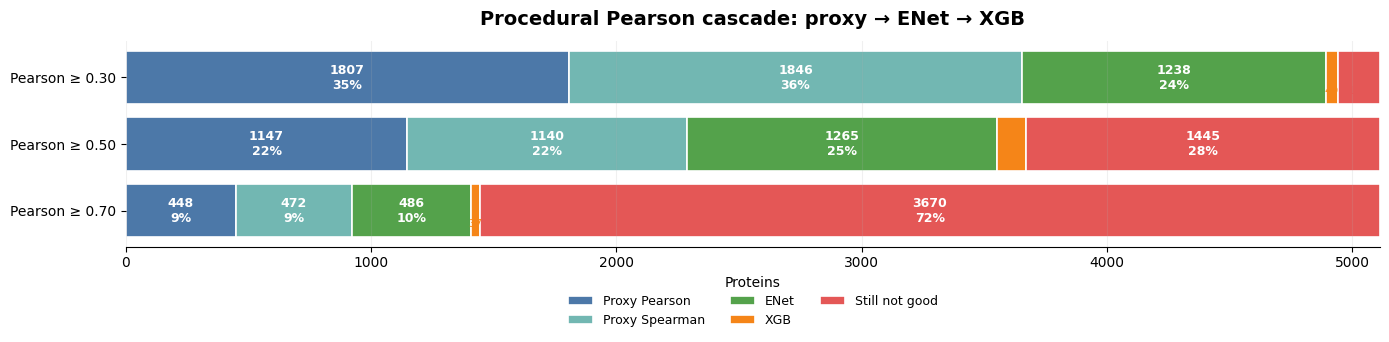

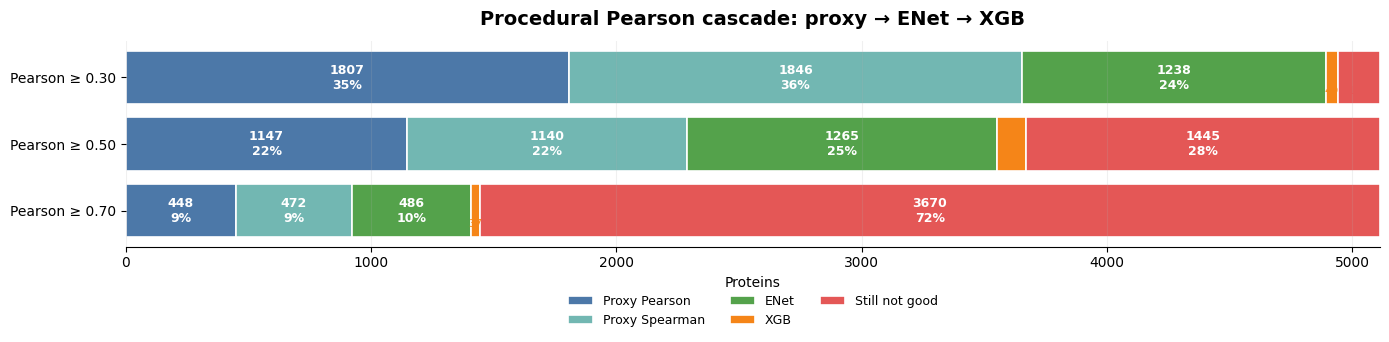

In [9]:
main_assignments = pd.concat(
    [procedural_pearson_cascade(thr, include_sc=False) for thr in PEARSON_GOOD_THRESHOLDS],
    ignore_index=True,
)

main_summary = summarize_assignments(main_assignments, order=CASCADE_ORDER_BASE)

print("Procedural Pearson cascade summary")
display(
    main_summary
    .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
    .reindex(columns=CASCADE_ORDER_BASE)
)

display(main_summary)

plot_stacked_partition_rows(
    main_summary,
    title="Procedural Pearson cascade: proxy → ENet → XGB",
    order=CASCADE_ORDER_BASE,
    save_name="pearson_cascade_030_050_070.png",
)

## 9. Pearson threshold sweep

This is the same procedural cascade, but for many Pearson-good thresholds. It shows how sensitive the conclusion is to the chosen definition of “predicted well.”

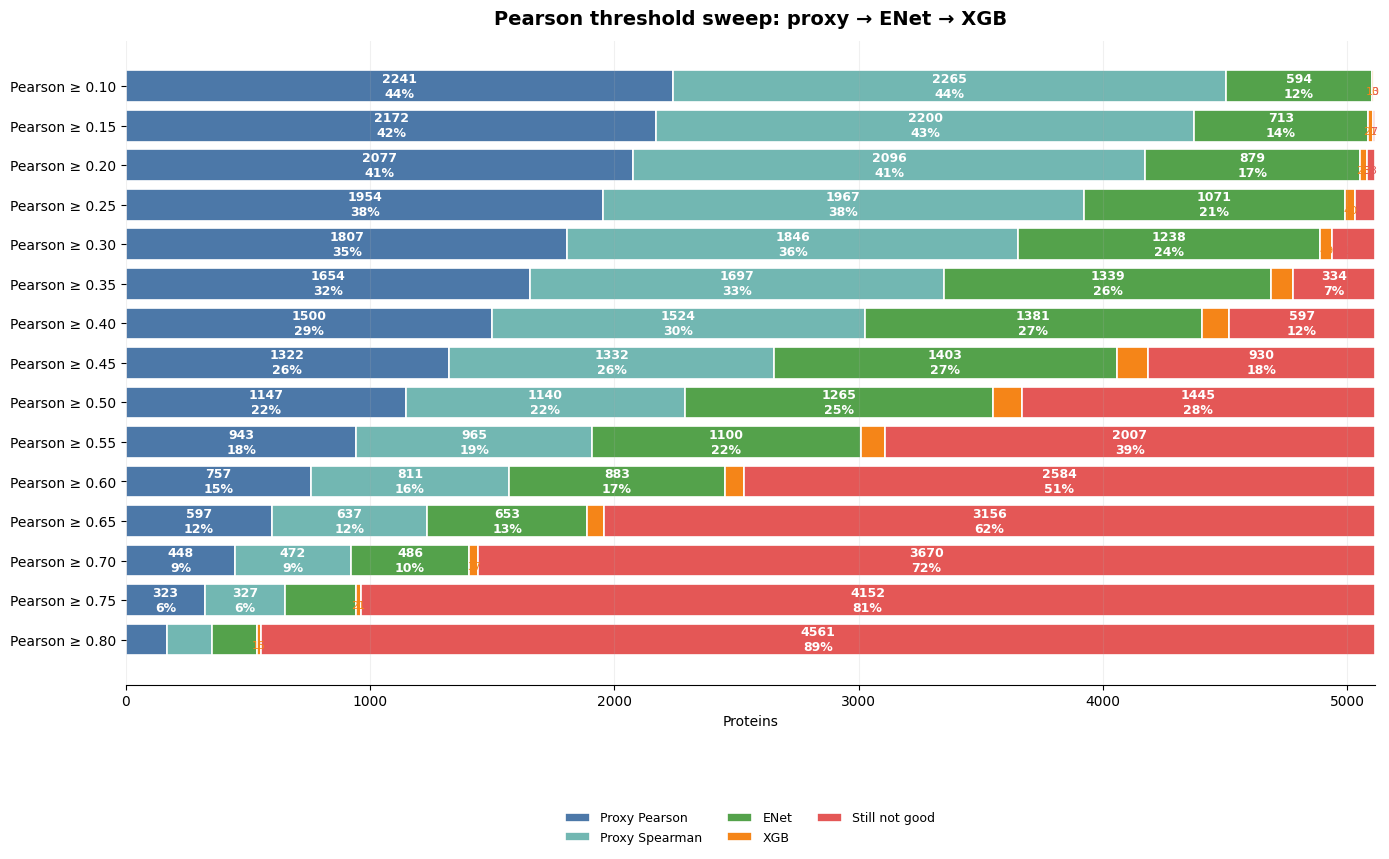

In [10]:
sweep_assignments = pd.concat(
    [procedural_pearson_cascade(thr, include_sc=False) for thr in PEARSON_SWEEP_THRESHOLDS],
    ignore_index=True,
)

sweep_summary = summarize_assignments(sweep_assignments, order=CASCADE_ORDER_BASE)

plot_stacked_partition_rows(
    sweep_summary,
    title="Pearson threshold sweep: proxy → ENet → XGB",
    order=CASCADE_ORDER_BASE,
    save_name="pearson_threshold_sweep.png",
    figsize=(14, max(5, 0.45 * len(PEARSON_SWEEP_THRESHOLDS) + 2.0)),
)

if SAVE_OUTPUTS:
    sweep_summary.to_csv(EXPORT_TABLE_DIR / "pearson_threshold_sweep_summary.csv", index=False)

## 10. Proxy-correlation threshold inspection

This asks a different question:

> If we only trust same-gene proxies whose full same-gene correlation is at least some threshold, how many proteins are eligible, and how many are actually predicted well on the held-out test split?

The bar segments are:

- Eligible and good.
- Eligible but not good.
- No eligible proxy.

In [16]:
def proxy_corr_threshold_assignments(proxy_type, pred_thresholds=PEARSON_GOOD_THRESHOLDS, corr_thresholds=PROXY_CORR_THRESHOLDS):
    proxy_df = proxy_results[proxy_results["proxy_type"].astype(str).eq(proxy_type)].copy()
    proxy_idx = _index_by_protein(proxy_df)
    rows = []

    for pred_thr in pred_thresholds:
        for corr_thr in corr_thresholds:
            for protein in protein_universe.astype(str):
                label = "No eligible proxy"
                metric = np.nan
                corr_val = np.nan

                if protein in proxy_idx.index:
                    row = proxy_idx.loc[protein]
                    corr_val = row.get("same_gene_corr_full", np.nan)
                    metric = row.get("test_pearson_corr", np.nan)
                    if np.isfinite(corr_val) and corr_val >= corr_thr:
                        if np.isfinite(metric) and metric >= pred_thr:
                            label = "Eligible and good"
                        else:
                            label = "Eligible but not good"

                rows.append({
                    "proxy_type": proxy_type,
                    "prediction_threshold": pred_thr,
                    "corr_threshold": corr_thr,
                    "threshold": corr_thr,
                    "stage": label,
                    "protein": protein,
                    "test_pearson_corr": metric,
                    "same_gene_corr_full": corr_val,
                })

    return pd.DataFrame(rows)


def plot_proxy_corr_grid(proxy_type, pred_threshold):
    assign = proxy_corr_threshold_assignments(
        proxy_type=proxy_type,
        pred_thresholds=[pred_threshold],
        corr_thresholds=PROXY_CORR_THRESHOLDS,
    )
    summary = summarize_assignments(
        assign,
        order=["Eligible and good", "Eligible but not good", "No eligible proxy"],
    )
    # Relabel y-axis from Pearson-good threshold to proxy-correlation threshold for this plot.
    fig, ax = plt.subplots(figsize=(14, max(3.2, 0.45 * len(PROXY_CORR_THRESHOLDS) + 1.8)))
    thresholds = list(summary["threshold"].drop_duplicates())
    max_total = int(summary.groupby("threshold")["total_proteins"].first().max())
    used_labels = set()
    order = ["Eligible and good", "Eligible but not good", "No eligible proxy"]

    for y, thr in enumerate(thresholds):
        sub = summary[summary["threshold"].eq(thr)]
        total = int(sub["total_proteins"].iloc[0])
        left = 0
        for stage in order:
            row = sub[sub["stage"].astype(str).eq(stage)]
            width = int(row["proteins"].iloc[0]) if len(row) else 0
            if width <= 0:
                continue
            pct = 100 * width / total if total else 0
            color = COLOR_MAP.get(stage, None)
            label = stage if stage not in used_labels else None
            ax.barh(y, width, left=left, color=color, edgecolor="white", linewidth=1.2, label=label)
            used_labels.add(stage)
            if pct >= 6:
                ax.text(left + width / 2, y, f"{width}\n{pct:.0f}%", ha="center", va="center", color="white", fontsize=9, weight="bold")
            left += width


## 11. MSE without a fixed threshold

MSE has no universal “good” threshold across proteins. This section avoids defining one.

Two compact inspections are used:

1. **Winner-only MSE partition**: each protein is assigned to the family with the lowest valid MSE.
2. **Procedural MSE improvement partition**: starting from proxy MSE, ENet/XGB are counted only if they improve lower-MSE performance.

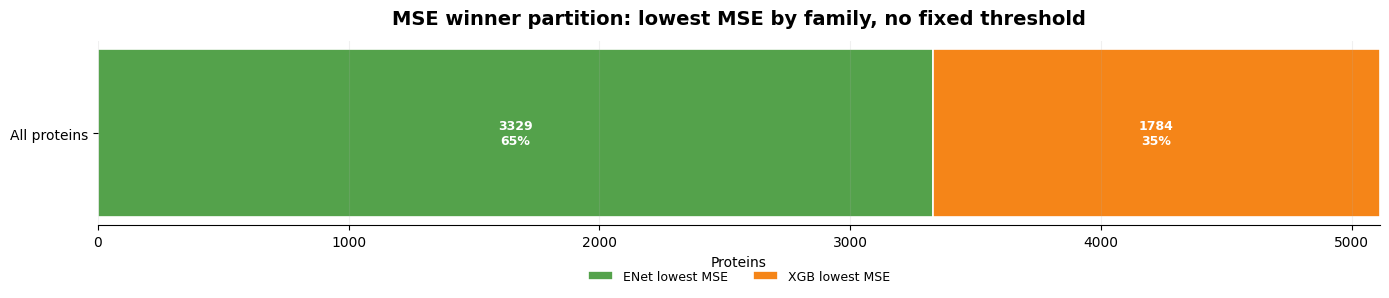

,stage,proteins,percent
0,ENet lowest MSE,3329,65.108547
1,XGB lowest MSE,1784,34.891453


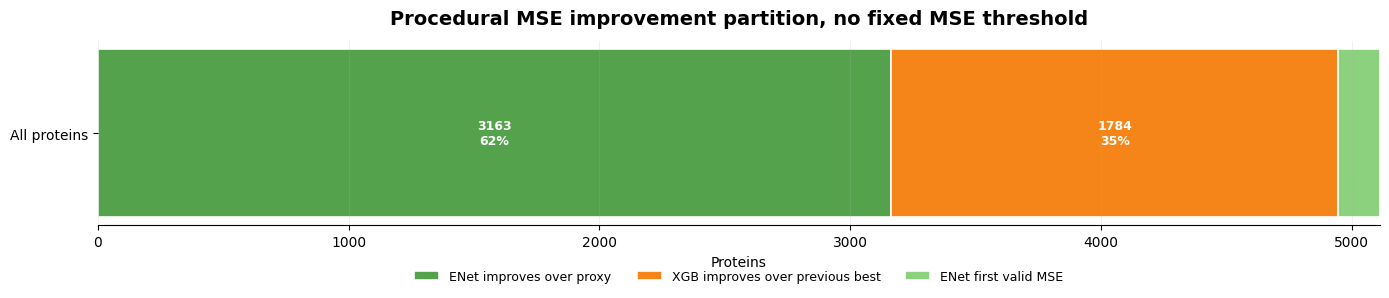

,stage,proteins,percent
0,ENet improves over proxy,3163,61.861921
1,XGB improves over previous best,1784,34.891453
2,ENet first valid MSE,166,3.246626


In [12]:
def mse_winner_assignments():
    proxy_idx = _index_by_protein(proxy_best_mse)
    enet_idx = _index_by_protein(enet_best_mse)
    xgb_idx = _index_by_protein(xgb_best_mse)
    rows = []

    for protein in protein_universe.astype(str):
        candidates = []
        for fam, idx in [("proxy", proxy_idx), ("enet", enet_idx), ("xgb", xgb_idx)]:
            if protein in idx.index:
                row = idx.loc[protein]
                mse = row.get("test_mse", np.nan)
                if np.isfinite(mse):
                    candidates.append((fam, mse, row))

        if not candidates:
            stage = "No valid MSE"
            value = np.nan
            run_label = ""
        else:
            fam, value, row = min(candidates, key=lambda x: x[1])
            if fam == "proxy":
                base = _proxy_label(row).replace("Proxy", "Proxy")
                stage = f"{base} lowest MSE"
            elif fam == "enet":
                stage = "ENet lowest MSE"
            else:
                stage = "XGB lowest MSE"
            run_label = row.get("run_label", "")

        rows.append({
            "protein": protein,
            "threshold": 0.0,
            "stage": stage,
            "test_mse": value,
            "run_label": run_label,
        })

    return pd.DataFrame(rows)


def mse_procedural_improvement_assignments():
    proxy_idx = _index_by_protein(proxy_best_mse)
    enet_idx = _index_by_protein(enet_best_mse)
    xgb_idx = _index_by_protein(xgb_best_mse)
    rows = []

    for protein in protein_universe.astype(str):
        proxy_mse = proxy_idx.loc[protein, "test_mse"] if protein in proxy_idx.index else np.nan
        enet_mse = enet_idx.loc[protein, "test_mse"] if protein in enet_idx.index else np.nan
        xgb_mse = xgb_idx.loc[protein, "test_mse"] if protein in xgb_idx.index else np.nan

        valid_proxy = np.isfinite(proxy_mse)
        valid_enet = np.isfinite(enet_mse)
        valid_xgb = np.isfinite(xgb_mse)

        if valid_proxy:
            current_best = proxy_mse
            stage = "Proxy retained / no lower MSE found"
            if valid_enet and enet_mse < current_best:
                current_best = enet_mse
                stage = "ENet improves over proxy"
            if valid_xgb and xgb_mse < current_best:
                current_best = xgb_mse
                stage = "XGB improves over previous best"
        elif valid_enet:
            current_best = enet_mse
            stage = "ENet first valid MSE"
            if valid_xgb and xgb_mse < current_best:
                current_best = xgb_mse
                stage = "XGB improves over previous best"
        elif valid_xgb:
            current_best = xgb_mse
            stage = "XGB first valid MSE"
        else:
            current_best = np.nan
            stage = "No valid comparison"

        rows.append({
            "protein": protein,
            "threshold": 0.0,
            "stage": stage,
            "best_mse": current_best,
            "proxy_mse": proxy_mse,
            "enet_mse": enet_mse,
            "xgb_mse": xgb_mse,
        })

    return pd.DataFrame(rows)


def plot_single_partition(assignments, title, order, save_name=None):
    tmp = assignments.copy()
    tmp["threshold"] = 0.0
    summary = summarize_assignments(tmp, order=order)
    plot_stacked_partition_rows(
        summary,
        title=title,
        order=order,
        xlabel="Proteins",
        save_name=save_name,
        figsize=(14, 3.2),
        row_label_func=lambda _: "All proteins",
    )
    display(
        summary[["stage", "proteins", "percent"]]
        .sort_values("stage")
        .reset_index(drop=True)
    )
    return summary

mse_winner = mse_winner_assignments()
mse_winner_order = MSE_WINNER_ORDER
mse_winner_summary = plot_single_partition(
    mse_winner,
    title="MSE winner partition: lowest MSE by family, no fixed threshold",
    order=mse_winner_order,
    save_name="mse_winner_partition.png",
)

mse_improvement = mse_procedural_improvement_assignments()
mse_improvement_order = [
    "Proxy retained / no lower MSE found",
    "ENet improves over proxy",
    "XGB improves over previous best",
    "ENet first valid MSE",
    "XGB first valid MSE",
    "No valid comparison",
]
mse_improvement_summary = plot_single_partition(
    mse_improvement,
    title="Procedural MSE improvement partition, no fixed MSE threshold",
    order=mse_improvement_order,
    save_name="mse_procedural_improvement_partition.png",
)

if SAVE_OUTPUTS:
    mse_winner.to_csv(EXPORT_TABLE_DIR / "mse_winner_assignments.csv", index=False)
    mse_improvement.to_csv(EXPORT_TABLE_DIR / "mse_procedural_improvement_assignments.csv", index=False)

## 12. Load scTranslator predictions from `.npz` bundles

This section expects the files to be in the same folder as the notebook:

```text
sc_predictions_2M.npz
sc_predictions_160K.npz
sc_predictions_10K.npz
```

The bundle format is assumed to contain:

```text
predictions
protein_names
cell_names
```

Predictions are reindexed to match `GT_scaled.index` and `GT_scaled.columns`, then evaluated on the exact ENet/XGB H5 test split.

In [13]:
def load_sctranslator_prediction_tables(bundle_paths=SCTRANSLATOR_BUNDLE_PATHS, gt=GT_scaled):
    pred_dfs = {}
    missing = []

    for label, path in bundle_paths.items():
        path = Path(path)
        if not path.exists():
            missing.append(str(path))
            continue

        bundle = np.load(path, allow_pickle=True)
        required = {"predictions", "protein_names", "cell_names"}
        missing_keys = required.difference(set(bundle.files))
        if missing_keys:
            raise KeyError(f"{path.name} is missing keys: {sorted(missing_keys)}")

        df = pd.DataFrame(
            bundle["predictions"],
            columns=[str(x) for x in bundle["protein_names"]],
        )
        df.index = [str(x) for x in bundle["cell_names"]]

        # Same reindexing logic as the snippet.
        df = df.reindex(index=gt.index.astype(str), columns=gt.columns.astype(str))
        pred_dfs[label] = df

    if missing:
        print("Missing scTranslator files; those labels will be skipped:")
        for m in missing:
            print("-", m)

    return pred_dfs


def evaluate_sctranslator_predictions(pred_dfs, gt=GT_scaled, eval_samples=None):
    if eval_samples is None:
        eval_samples = gt.index
    eval_samples = pd.Index(eval_samples.astype(str)).intersection(gt.index.astype(str))

    rows = []
    for label, pred_df in pred_dfs.items():
        common_cols = gt.columns.astype(str).intersection(pred_df.columns.astype(str))
        for protein in common_cols:
            y_true = gt.loc[eval_samples, protein].to_numpy(dtype=float)
            y_pred = pred_df.loc[eval_samples, protein].to_numpy(dtype=float)
            metrics = compute_metrics(y_true, y_pred)
            rows.append({
                "protein": str(protein),
                "run_label": f"scTranslator {label}",
                "model_family": "sctranslator",
                "family_group": "sctranslator",
                "sc_size": str(label),
                "source_folder": "scTranslator npz",
                "test_mse": metrics["test_mse"],
                "test_pearson_corr": metrics["test_pearson_corr"],
                "test_cosine_similarity": metrics["test_cosine_similarity"],
                "n_test_used": metrics.get("n_test_used", np.nan),
                "train_n": np.nan,
                "test_n": len(eval_samples),
                "split_hash": model_split_hash,
                "h5_path": "",
            })

    return pd.DataFrame(rows)

sctranslator_pred_dfs = load_sctranslator_prediction_tables()
sctranslator_results = evaluate_sctranslator_predictions(
    sctranslator_pred_dfs,
    gt=GT_scaled,
    eval_samples=test_samples,
)

sctranslator_results = add_family_group(sctranslator_results)

print("scTranslator result rows:", len(sctranslator_results))
if len(sctranslator_results):
    display(
        sctranslator_results.groupby("run_label")
        .agg(
            proteins=("protein", "nunique"),
            pearson_median=("test_pearson_corr", "median"),
            pearson_mean=("test_pearson_corr", "mean"),
            mse_median=("test_mse", "median"),
        )
        .sort_values("pearson_median", ascending=False)
    )
    display(sctranslator_results.head())
else:
    print("No scTranslator predictions were loaded. The final rescue plots below will be skipped.")

scTranslator result rows: 15339


,proteins,pearson_median,pearson_mean,mse_median
run_label,,,,
scTranslator 160K,5113,-0.004724,-0.007454,13198.581632
scTranslator 2M,5113,-0.005029,-0.003427,11707.122961
scTranslator 10K,5113,-0.012217,-0.011571,0.674487


,protein,run_label,model_family,family_group,sc_size,source_folder,test_mse,test_pearson_corr,test_cosine_similarity,n_test_used,train_n,test_n,split_hash,h5_path
0,A2M,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,1929.069576,-0.188503,0.354583,74,NaN,74,d0750f1c44a2,
1,AAAS,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,2553.709484,-0.005944,-0.149269,74,NaN,74,d0750f1c44a2,
2,AACS,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,47197.703064,0.012968,0.062528,74,NaN,74,d0750f1c44a2,
3,AAGAB,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,616.272881,0.181502,0.032709,74,NaN,74,d0750f1c44a2,
4,AAK1,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,87522.725488,0.310178,-0.129605,74,NaN,74,d0750f1c44a2,


## 13. Final question: among proteins not predicted well by proxy, ENet, or XGB, does scTranslator perform well?

For each Pearson threshold, this section first runs the base cascade:

```text
Proxy → ENet → XGB
```

Then it takes only the proteins still not predicted well and asks whether the best scTranslator prediction reaches the same Pearson threshold.

Full procedural cascade with scTranslator as final rescue


stage,Proxy Pearson,Proxy Spearman,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,,
0.3,1807,1846,1238,49,1,1,0,171
0.5,1147,1140,1265,116,0,0,0,1445
0.7,448,472,486,37,0,0,0,3670


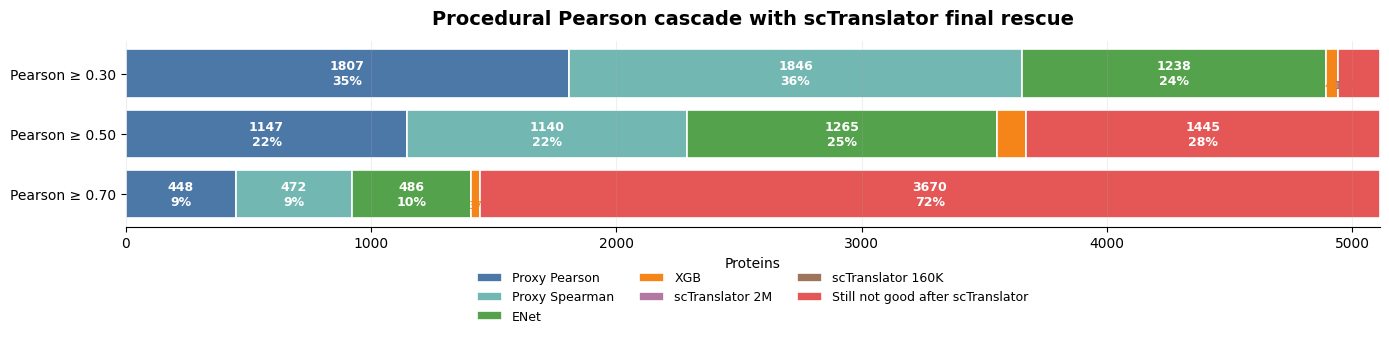

Focused scTranslator rescue among proxy/ENet/XGB failures


stage,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,
0.3,1,1,0,171
0.5,0,0,0,1445
0.7,0,0,0,3670


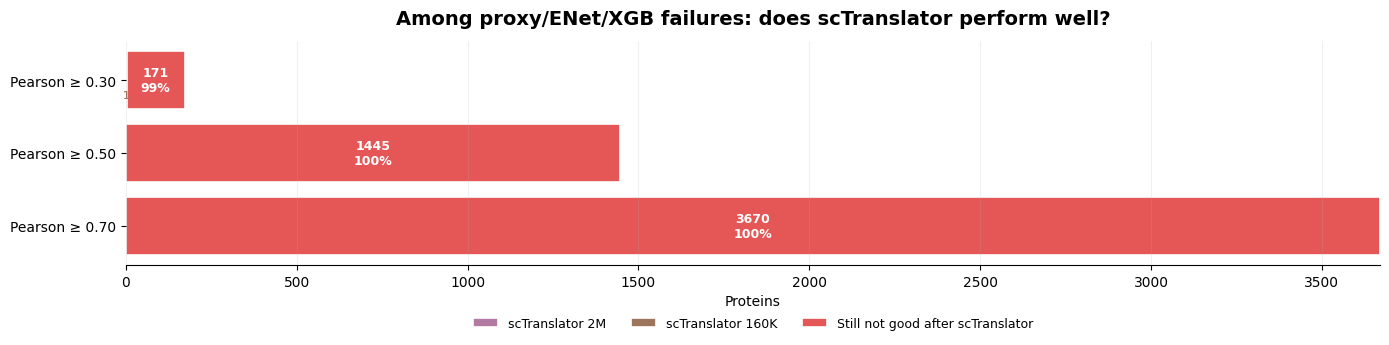

In [14]:
if len(sctranslator_results) > 0:
    sctranslator_best_pearson = best_per_protein(sctranslator_results, "test_pearson_corr", higher=True)

    sc_assignments = pd.concat(
        [
            procedural_pearson_cascade(
                thr,
                include_sc=True,
                sctranslator_best=sctranslator_best_pearson,
            )
            for thr in PEARSON_GOOD_THRESHOLDS
        ],
        ignore_index=True,
    )

    sc_summary = summarize_assignments(sc_assignments, order=CASCADE_ORDER_WITH_SC)

    print("Full procedural cascade with scTranslator as final rescue")
    display(
        sc_summary
        .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
        .reindex(columns=CASCADE_ORDER_WITH_SC)
    )

    plot_stacked_partition_rows(
        sc_summary,
        title="Procedural Pearson cascade with scTranslator final rescue",
        order=CASCADE_ORDER_WITH_SC,
        save_name="pearson_cascade_with_sctranslator.png",
    )

    # Focused answer: among base failures only, how many are rescued by scTranslator?
    focused_rows = []
    for thr in PEARSON_GOOD_THRESHOLDS:
        base = procedural_pearson_cascade(thr, include_sc=False)
        base_failures = set(base.loc[base["stage"].eq("Still not good"), "protein"].astype(str))

        sc_best_idx = _index_by_protein(sctranslator_best_pearson)
        for protein in sorted(base_failures):
            if protein in sc_best_idx.index:
                row = sc_best_idx.loc[protein]
                value = row.get("test_pearson_corr", np.nan)
                if np.isfinite(value) and value >= thr:
                    stage = f"scTranslator {row.get('sc_size', row.get('run_label', '')).replace('scTranslator ', '')}"
                else:
                    stage = "Still not good after scTranslator"
            else:
                value = np.nan
                stage = "Still not good after scTranslator"

            focused_rows.append({
                "protein": protein,
                "threshold": thr,
                "stage": stage,
                "test_pearson_corr": value,
            })

    sc_rescue_only = pd.DataFrame(focused_rows)
    sc_rescue_summary = summarize_assignments(
        sc_rescue_only,
        order=["scTranslator 2M", "scTranslator 160K", "scTranslator 10K", "Still not good after scTranslator"],
    )

    print("Focused scTranslator rescue among proxy/ENet/XGB failures")
    display(
        sc_rescue_summary
        .pivot_table(index="threshold", columns="stage", values="proteins", fill_value=0, aggfunc="sum")
        .reindex(columns=["scTranslator 2M", "scTranslator 160K", "scTranslator 10K", "Still not good after scTranslator"])
    )

    plot_stacked_partition_rows(
        sc_rescue_summary,
        title="Among proxy/ENet/XGB failures: does scTranslator perform well?",
        order=["scTranslator 2M", "scTranslator 160K", "scTranslator 10K", "Still not good after scTranslator"],
        save_name="sctranslator_rescue_after_failures.png",
    )

    if SAVE_OUTPUTS:
        sctranslator_results.to_csv(EXPORT_TABLE_DIR / "sctranslator_metrics.csv", index=False)
        sc_assignments.to_csv(EXPORT_TABLE_DIR / "pearson_cascade_with_sctranslator_assignments.csv", index=False)
        sc_rescue_only.to_csv(EXPORT_TABLE_DIR / "sctranslator_rescue_only_assignments.csv", index=False)
        sc_summary.to_csv(EXPORT_TABLE_DIR / "pearson_cascade_with_sctranslator_summary.csv", index=False)
        sc_rescue_summary.to_csv(EXPORT_TABLE_DIR / "sctranslator_rescue_only_summary.csv", index=False)
else:
    print("Skipped: no scTranslator predictions were loaded.")

## 14. Optional: export final base tables

Set `SAVE_OUTPUTS = True` in the setup cell to save tables and figures automatically.

In [15]:
if SAVE_OUTPUTS:
    all_results.to_csv(EXPORT_TABLE_DIR / "all_results_proxy_enet_xgb.csv", index=False)
    proxy_results.to_csv(EXPORT_TABLE_DIR / "proxy_results_all_same_gene.csv", index=False)
    main_assignments.to_csv(EXPORT_TABLE_DIR / "pearson_cascade_assignments_030_050_070.csv", index=False)
    main_summary.to_csv(EXPORT_TABLE_DIR / "pearson_cascade_summary_030_050_070.csv", index=False)
    mse_winner.to_csv(EXPORT_TABLE_DIR / "mse_winner_assignments.csv", index=False)
    mse_improvement.to_csv(EXPORT_TABLE_DIR / "mse_improvement_assignments.csv", index=False)
    print("Saved outputs to:")
    print("-", EXPORT_TABLE_DIR)
    print("-", FIGURE_DIR)
else:
    print("SAVE_OUTPUTS is False. Change it to True in the setup cell to export CSVs and figures.")

SAVE_OUTPUTS is False. Change it to True in the setup cell to export CSVs and figures.
